Liquid bin-width evaluation:   0%|          | 0/30 [00:00<?, ?rep/s]

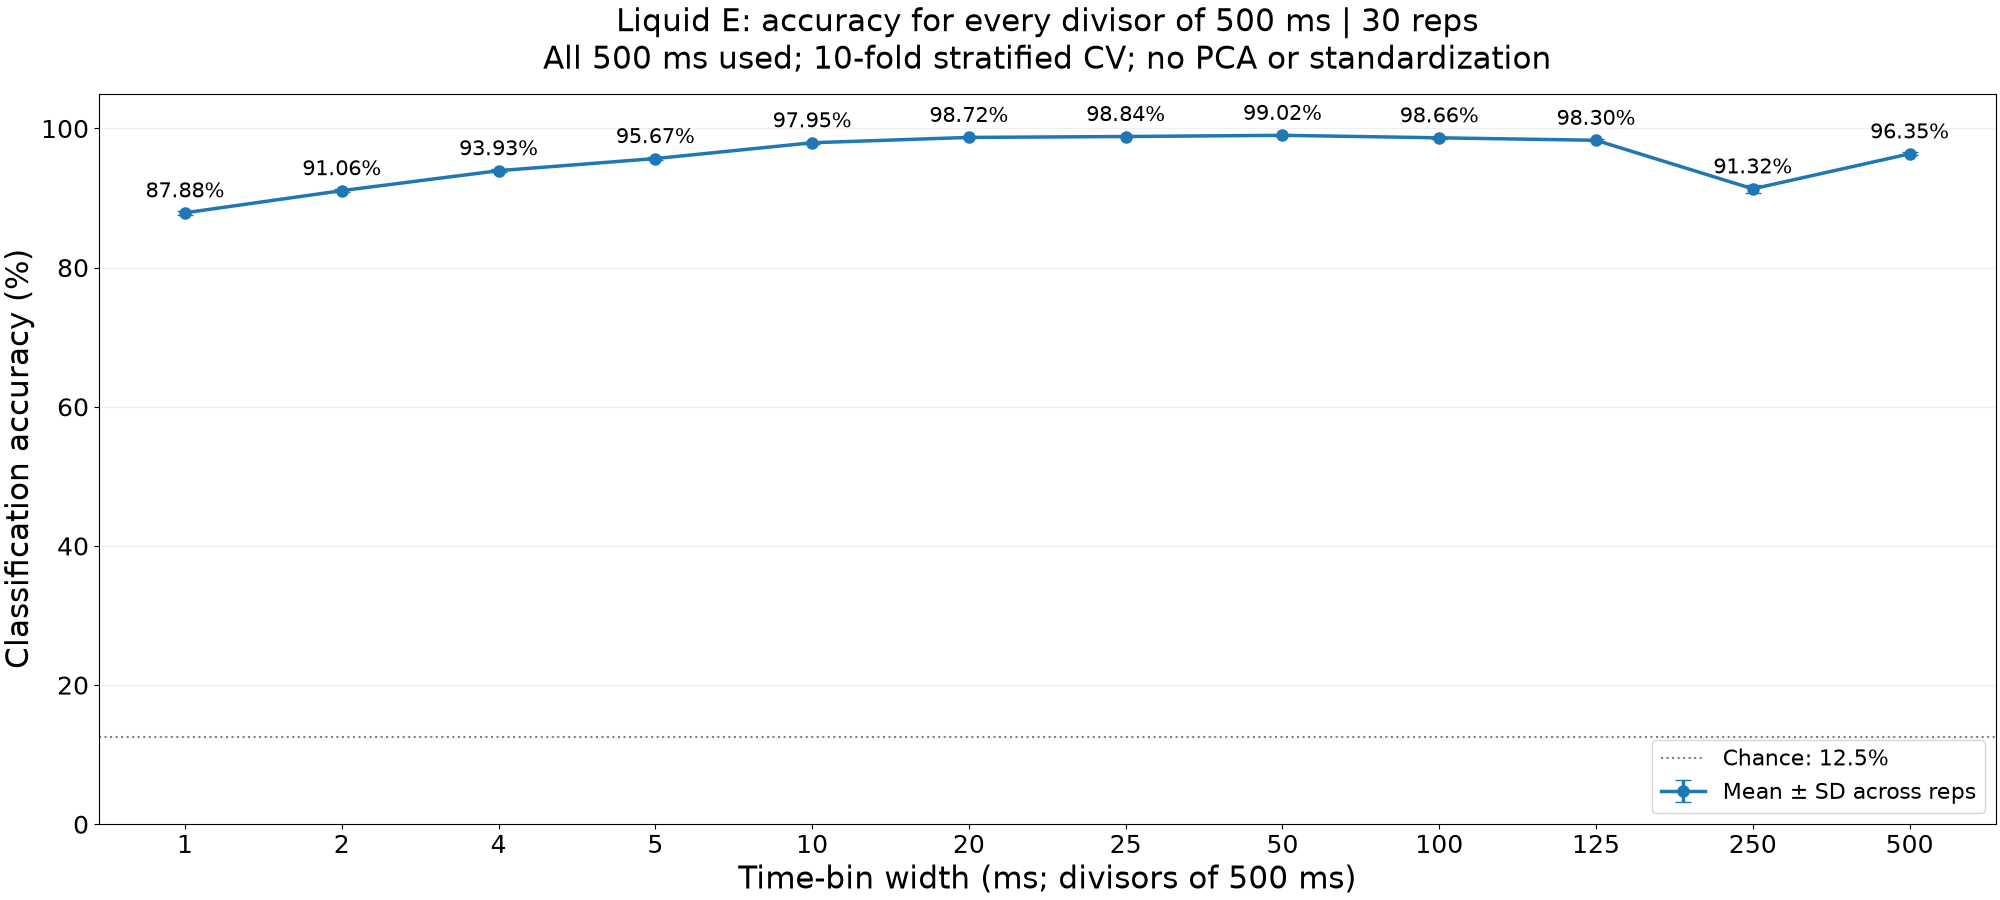

  1 ms × 500 bins: 87.881% ± 0.270%
  2 ms × 250 bins: 91.062% ± 0.204%
  4 ms × 125 bins: 93.933% ± 0.178%
  5 ms × 100 bins: 95.675% ± 0.181%
 10 ms ×  50 bins: 97.946% ± 0.128%
 20 ms ×  25 bins: 98.715% ± 0.089%
 25 ms ×  20 bins: 98.844% ± 0.091%
 50 ms ×  10 bins: 99.017% ± 0.091%
100 ms ×   5 bins: 98.658% ± 0.126%
125 ms ×   4 bins: 98.302% ± 0.140%
250 ms ×   2 bins: 91.323% ± 0.553%
500 ms ×   1 bins: 96.352% ± 0.232%


In [ ]:
# Liquidの各repの混同行列を合算する（分類の再実行・結果ファイルの保存はしない）。
from pathlib import Path
from zipfile import ZipFile
from xml.etree import ElementTree as ET
import posixpath
import sys
import numpy as np
import matplotlib.pyplot as plt

# ノートブックをLSM直下・h_analysis・研究コード直下のいずれから開いても探す。
project_root = next(
    (root for parent in (Path.cwd(), *Path.cwd().parents)
     for root in (parent, parent / "LSM")
     if (root / "d_tools" / "evaluation_excel.py").is_file()), None
)
if project_root is None:
    raise FileNotFoundError("LSMフォルダからノートブックを開いてください。")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from d_tools.evaluation_excel import load_classification_results

# Noneなら保存済みの全repを使用。例：[1, 2, 3, 4, 5]で対象を限定できる。
REPS = None
BIN_MS = 25.0
results_root = project_root / "g_tactile_results" / "liquid_run"


def read_confusion_counts(workbook_path, block_index):
    """指定した評価時間窓の8素材の個数を、Excelのconf_8clsシートから読む。"""
    ns = {"s": "http://schemas.openxmlformats.org/spreadsheetml/2006/main"}
    with ZipFile(workbook_path) as archive:
        workbook = ET.fromstring(archive.read("xl/workbook.xml"))
        sheet = next(s for s in workbook.findall("s:sheets/s:sheet", ns)
                     if s.get("name") == "conf_8cls")
        relations = {r.get("Id"): r.get("Target") for r in ET.fromstring(
            archive.read("xl/_rels/workbook.xml.rels"))}
        target = relations[sheet.get("{http://schemas.openxmlformats.org/officeDocument/2006/relationships}id")]
        target = target.lstrip("/") if target.startswith("/") else posixpath.normpath(posixpath.join("xl", target))
        cells = {c.get("r"): c for c in ET.fromstring(archive.read(target)).findall("s:sheetData/s:row/s:c", ns)}
        counts = np.array([[float(cells[f"{col}{row}"].find("s:v", ns).text)
                            for col in "BCDEFGHI"]
                           for row in range(2 + 12 * block_index, 10 + 12 * block_index)])
    if np.any(counts < 0) or not np.all(np.isfinite(counts)) or not np.all(counts == np.floor(counts)):
        raise ValueError(f"混同行列の個数が不正です：{workbook_path}")
    return counts.astype(np.int64)


# 同一の素材順・時間窓・分割数の結果だけを合算する。
rep_dirs = sorted((p for p in results_root.glob("rep*")
                   if p.is_dir() and p.name[3:].isdigit()), key=lambda p: int(p.name[3:]))
if REPS is not None:
    missing = set(REPS) - {int(p.name[3:]) for p in rep_dirs}
    if missing:
        raise FileNotFoundError(f"見つからないrep：{sorted(missing)}")
    rep_dirs = [p for p in rep_dirs if int(p.name[3:]) in REPS]
combined_counts = np.zeros((8, 8), dtype=np.int64)
used_reps, per_rep_accuracies = [], []
# 各repの行正規化割合を保持する。
per_rep_percentages = []
materials, folds = None, None
for rep_dir in rep_dirs:
    workbook_path = rep_dir / "test" / "eval" / "classification.xlsx"
    if not workbook_path.is_file():
        print(f"未完了のためスキップ：{rep_dir.name}")
        continue
    metadata = load_classification_results(workbook_path)
    if metadata is None:
        raise ValueError(f"評価条件を読み込めません：{workbook_path}")
    conditions = [i for i, value in enumerate(metadata["T_n_ms"])
                  if np.isclose(float(value), BIN_MS)]
    if len(conditions) != 1:
        raise ValueError(f"{rep_dir.name}に{BIN_MS:g} msの評価が一つだけ存在する必要があります。")
    if materials is None:
        materials, folds = metadata["materials"], metadata["folds"]
    if metadata["materials"] != materials or metadata["folds"] != folds:
        raise ValueError(f"素材順または分割数が異なります：{rep_dir.name}")
    counts = read_confusion_counts(workbook_path, conditions[0])
    if counts.sum() == 0 or np.any(counts.sum(axis=1) == 0):
        raise ValueError(f"評価個数が空です：{rep_dir.name}")
    accuracy = np.trace(counts) / counts.sum()
    summary = next(s for s in metadata["summary"] if np.isclose(float(s["T_n_ms"]), BIN_MS))
    if not np.isclose(accuracy, summary["accuracy"]):
        raise ValueError(f"個数と記録済み正答率が一致しません：{rep_dir.name}")
    per_rep_percentages.append(counts / counts.sum(axis=1, keepdims=True) * 100)
    combined_counts += counts
    used_reps.append(int(rep_dir.name[3:]))
    per_rep_accuracies.append(accuracy * 100)
if not used_reps:
    raise FileNotFoundError(f"集計できる評価結果がありません：{results_root}")

# 色は正解素材ごとの割合。各マスに合算個数と割合を併記する。
# 500 msのすべての整数約数を時間ビン幅にし、500 ms全体の分類精度を比較する。
# 時間区間を別々に分類するのではなく、全区間×全Eニューロンを特徴量にする。
from concurrent.futures import ThreadPoolExecutor, as_completed
from sklearn.model_selection import StratifiedKFold
from threadpoolctl import threadpool_limits
from tqdm.auto import tqdm
from d_tools.evaluation import extract_features
from d_tools.classification import classify
from d_tools.recording_io import read_record

DURATION_MS = 500
BIN_WIDTHS_MS = [width for width in range(1, DURATION_MS + 1) if DURATION_MS % width == 0]
# repごとに並列化する。メモリが足りない場合は1または2にする。
BIN_EVAL_WORKERS = 4



def predict_large_feature_fold(features, labels, train, test, gram):
    """通常と同じ正則化Mahalanobis距離を、試行間の内積から計算する。

    高次元でのSVDの繰り返しを避ける。共分散の非零固有値と射影を使い、
    PCAによる切り捨てや標準化は行わない。学習側が全ゼロの特徴量も除外する。
    """
    from scipy.linalg import eigh

    active = np.any(features[train] != 0, axis=0)
    test_norm = np.square(features[test][:, active]).sum(axis=1)
    distances = []
    regularization = 1e-6
    for label in np.unique(labels):
        class_train = train[labels[train] == label]
        class_gram = gram[np.ix_(class_train, class_train)]
        class_row_mean = class_gram.mean(axis=0)
        class_mean = class_gram.mean()
        centered = (class_gram - class_row_mean[None, :]
                    - class_row_mean[:, None] + class_mean)
        eigenvalues, eigenvectors = eigh(centered, check_finite=False)
        # 数値丸めで現れる零固有値だけを除く。非零成分はすべて使用する。
        tolerance = max(float(eigenvalues.max()), 1.0) * len(class_train) * np.finfo(float).eps
        valid = eigenvalues > tolerance
        eigenvalues, eigenvectors = eigenvalues[valid], eigenvectors[:, valid]
        cross = gram[np.ix_(test, class_train)]
        cross_mean = cross.mean(axis=1)
        centered_cross = cross - cross_mean[:, None] - class_row_mean[None, :] + class_mean
        projection_squared = np.square(centered_cross @ eigenvectors / np.sqrt(eigenvalues))
        delta_norm = test_norm - 2 * cross_mean + class_mean
        residual_norm = np.maximum(delta_norm - projection_squared.sum(axis=1), 0.0)
        variance = eigenvalues / (len(class_train) - 1)
        distances.append(residual_norm / regularization
                         + (projection_squared / (variance + regularization)).sum(axis=1))
    return np.unique(labels)[np.argmin(np.asarray(distances).T, axis=1)]


def evaluate_liquid_bin_widths(rep):
    """保存済み1 ms発火数から、同じCV分割・分類器で全時間幅を評価する。"""
    test_dir = results_root / f"rep{rep}" / "test"
    info = read_record(test_dir / "test_config_snapshot.json")
    if info["materials"] != materials or info.get("evaluation_population") != "E":
        raise ValueError(f"素材順または評価集団が異なります：rep{rep}")
    neuron_ids = np.asarray(info["evaluation_neuron_ids"], dtype=int)
    record_bin_ms = float(info["recording_bin_width_ms"])
    if not np.isclose(record_bin_ms, 1.0):
        raise ValueError(f"1 ms幅の記録が必要です：rep{rep}")
    path = test_dir / "rec" / "Liquid" / f"sliq_rec_rep{rep}.npy"
    recorded = np.load(path, mmap_mode="r", allow_pickle=False)
    try:
        if recorded.ndim != 4 or recorded.shape[0] != len(materials) or recorded.shape[-1] != DURATION_MS:
            raise ValueError(f"500 msの発火記録ではありません：rep{rep}")
        counts = np.asarray(recorded[:, :, neuron_ids, :])
    finally:
        recorded._mmap.close()
    labels = np.repeat(np.arange(len(materials)), counts.shape[1])
    # 通常evalと同じrep依存seed。すべてのビン幅で試行の分割を共通にする。
    cv_seed = int(info["eval"]["EVAL_BASE_SEED"]) + rep - 1
    splits = list(StratifiedKFold(n_splits=folds, shuffle=True, random_state=cv_seed)
                  .split(np.zeros((len(labels), 1)), labels))
    accuracies = []
    for width in BIN_WIDTHS_MS:
        features = extract_features(counts, width, bin_width_ms=record_bin_ms).reshape(len(labels), -1)
        predicted = np.empty_like(labels)
        # 特徴数が多いときだけ、同じ距離式を内積行列で評価する。
        gram = features @ features.T if features.shape[1] > 1000 else None
        for fold_index, (train, test) in enumerate(splits):
            # 学習側だけを使い、発火しない特徴量を除く。PCA・標準化は行わない。
            active = np.any(features[train] != 0, axis=0)
            if not active.any():
                raise ValueError(f"分類器の学習側に発火がありません：rep{rep}, {width} ms")
            if gram is None:
                predicted[test] = classify(features[train][:, active], labels[train], features[test][:, active])
            else:
                predicted[test] = predict_large_feature_fold(features, labels, train, test, gram)
                # 最初のrepの各時間幅で、既存の分類器との予測一致も照合する。
                if rep == used_reps[0] and fold_index == 0:
                    direct = classify(features[train][:, active], labels[train], features[test][:, active])
                    if not np.array_equal(predicted[test], direct):
                        raise AssertionError(f"通常の分類器と予測が異なります：{width} ms")
        accuracy = float(np.mean(predicted == labels) * 100)
        accuracies.append(accuracy)
        # 25 msの再計算が既存のExcelと一致することを確認する。
        if width == BIN_MS:
            reference = per_rep_accuracies[used_reps.index(rep)]
            if not np.isclose(accuracy, reference):
                raise ValueError(f"保存済み正答率と一致しません：rep{rep}, {width} ms")
    return rep, accuracies


# 1 ms幅では80×500＝40,000特徴になるため、細かいビンほど計算量が大きい。
bin_accuracy_by_rep = {}
with threadpool_limits(limits=1):
    with ThreadPoolExecutor(max_workers=min(BIN_EVAL_WORKERS, len(used_reps))) as executor:
        jobs = {executor.submit(evaluate_liquid_bin_widths, rep): rep for rep in used_reps}
        for future in tqdm(as_completed(jobs), total=len(jobs), desc="Liquid bin-width evaluation", unit="rep"):
            rep, accuracies = future.result()
            bin_accuracy_by_rep[rep] = accuracies
bin_accuracy_array = np.asarray([bin_accuracy_by_rep[rep] for rep in used_reps])
bin_accuracy_mean = bin_accuracy_array.mean(axis=0)
bin_accuracy_sd = (bin_accuracy_array.std(axis=0, ddof=1) if len(used_reps) > 1
                   else np.zeros(len(BIN_WIDTHS_MS)))
positions = np.arange(len(BIN_WIDTHS_MS))
fig, ax = plt.subplots(figsize=(20, 9), layout="constrained")
# 平均正答率を点付きの折れ線で結び、rep間の標準偏差をエラーバーで示す。
ax.errorbar(positions, bin_accuracy_mean, yerr=bin_accuracy_sd,
            fmt="o-", linewidth=2.5, markersize=8, capsize=6,
            color="tab:blue", label="Mean ± SD across reps")
for x, mean in zip(positions, bin_accuracy_mean):
    ax.text(x, mean + 1.5, f"{mean:.2f}%", ha="center", va="bottom", fontsize=15)
ax.set_xticks(positions, [str(width) for width in BIN_WIDTHS_MS])
ax.set_xlabel("Time-bin width (ms; divisors of 500 ms)", fontsize=22)
ax.set_ylabel("Classification accuracy (%)", fontsize=22)
ax.set_title(f"Liquid E: accuracy for every divisor of 500 ms | {len(used_reps)} reps\n"
             f"All 500 ms used; {folds}-fold stratified CV", fontsize=22, pad=18)
ax.set_ylim(0, max(105, float(np.max(bin_accuracy_mean + bin_accuracy_sd)) + 5))
ax.axhline(100 / len(materials), color="gray", linestyle=":", label=f"Chance: {100 / len(materials):g}%")
ax.tick_params(axis="both", labelsize=18)
ax.grid(axis="y", alpha=0.2)
ax.legend(fontsize=16, loc="lower right")
plt.show()
for width, mean, sd in zip(BIN_WIDTHS_MS, bin_accuracy_mean, bin_accuracy_sd):
    print(f"{width:3d} ms × {DURATION_MS // width:3d} bins: {mean:.3f}% ± {sd:.3f}%")


Liquid confusion | 25 ms:   0%|          | 0/30 [00:00<?, ?rep/s]

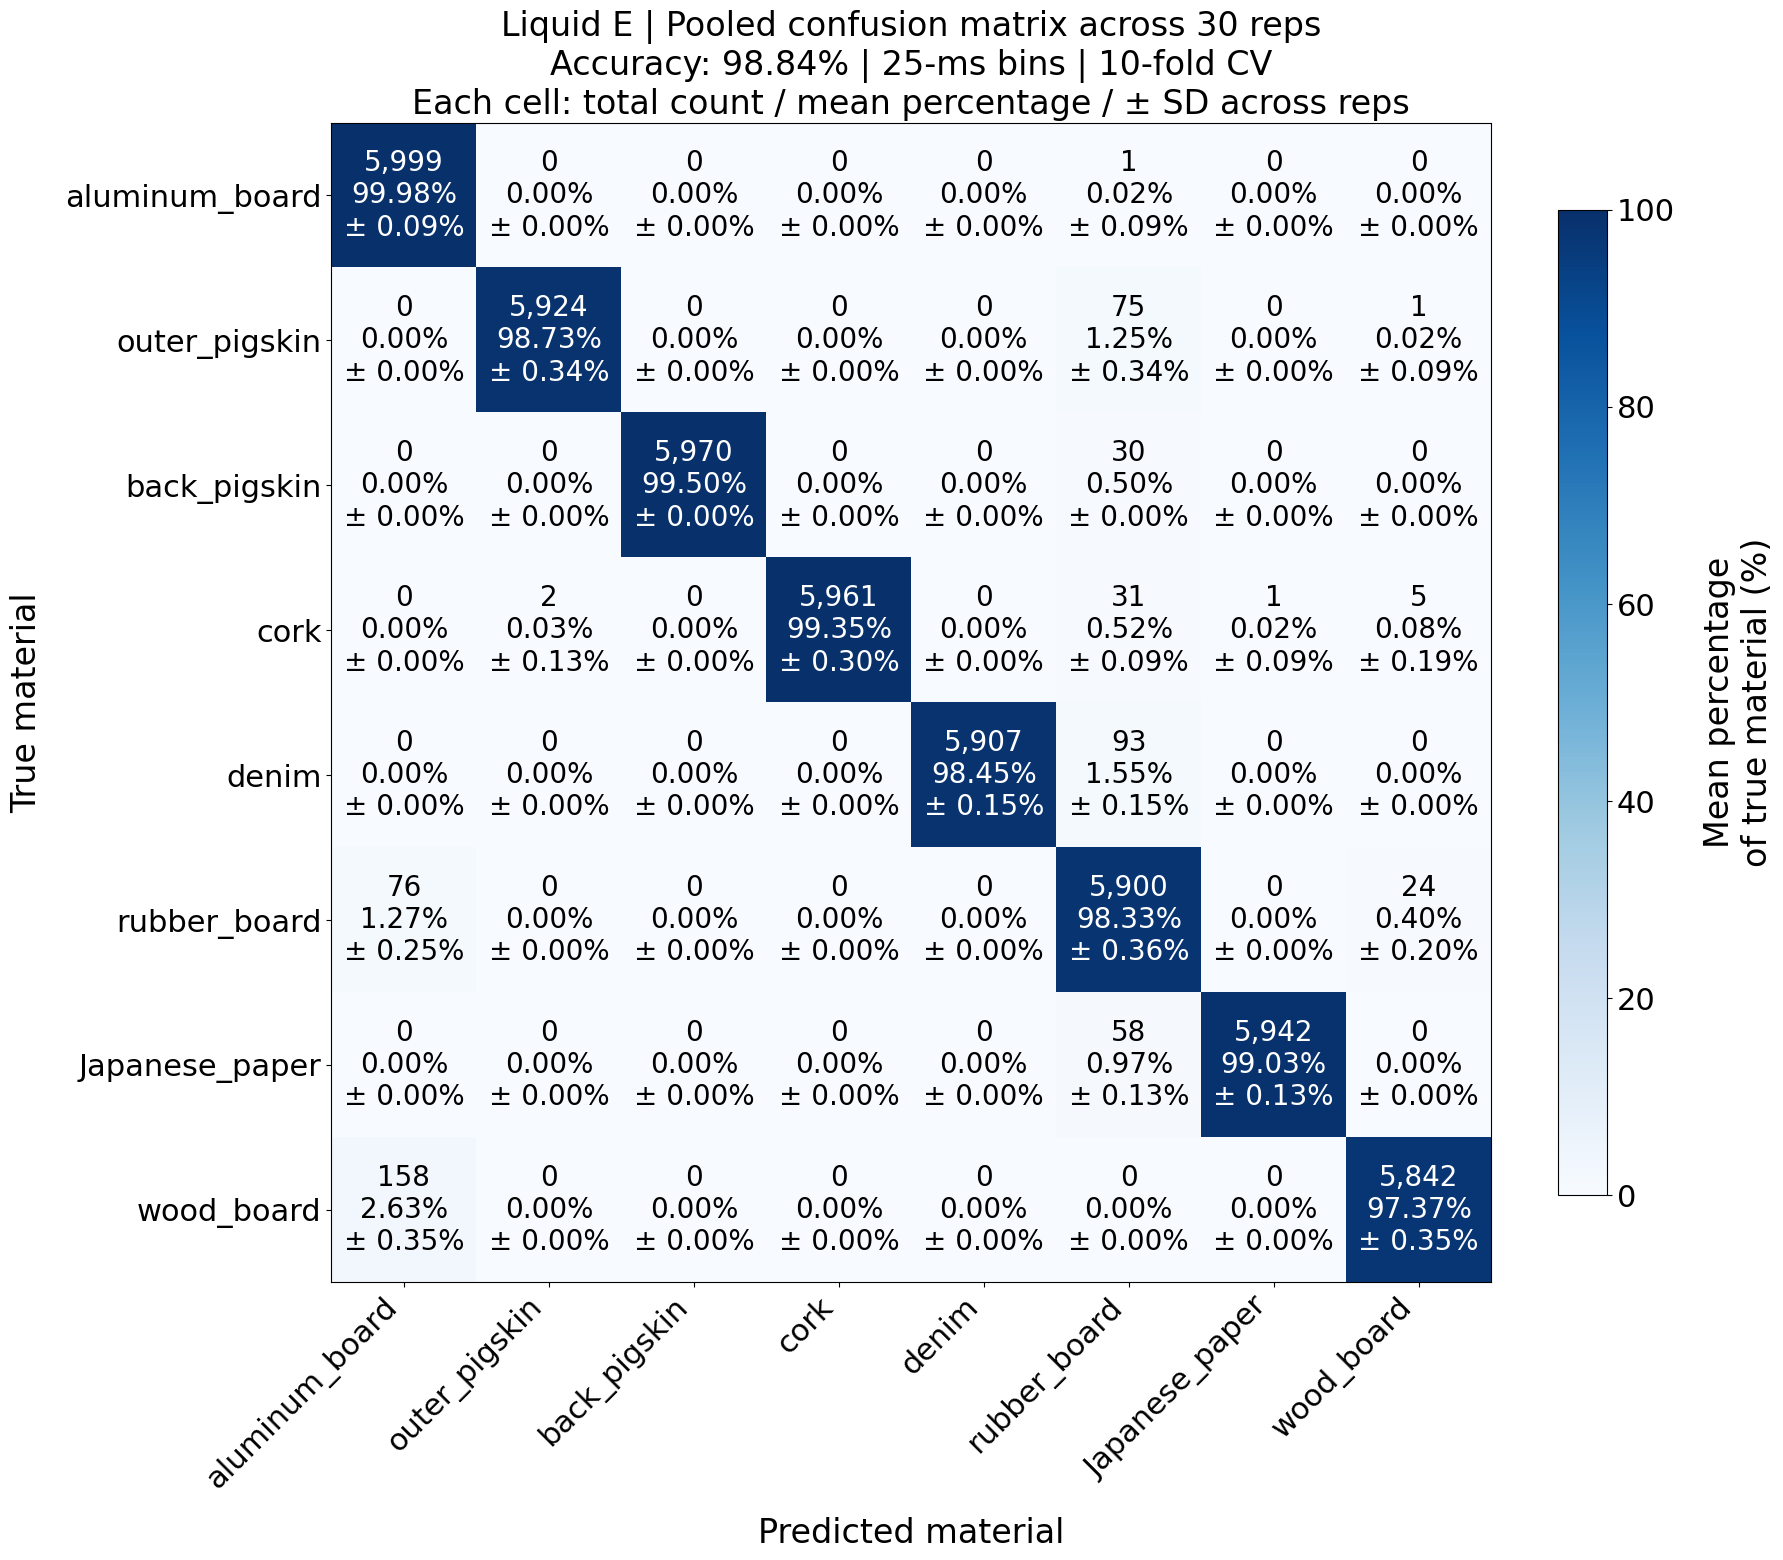

対象rep：[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
合計評価数：48,000（同じ元試行でもrepごとに別の評価として集計）
合算正答率：98.844%
rep正答率の平均：98.844%、SD：0.091ポイント


In [2]:
# Liquidの各repの混同行列を合算する。指定ビンの保存結果がなければ発火記録から再評価する。
from pathlib import Path
from zipfile import ZipFile
from xml.etree import ElementTree as ET
import posixpath
import sys
import numpy as np
import matplotlib.pyplot as plt

# ノートブックをLSM直下・h_analysis・研究コード直下のいずれから開いても探す。
project_root = next(
    (root for parent in (Path.cwd(), *Path.cwd().parents)
     for root in (parent, parent / "LSM")
     if (root / "d_tools" / "evaluation_excel.py").is_file()), None
)
if project_root is None:
    raise FileNotFoundError("LSMフォルダからノートブックを開いてください。")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from d_tools.evaluation_excel import load_classification_results
from d_tools.evaluation import extract_features
from d_tools.classification import classify
from d_tools.recording_io import read_record
from sklearn.model_selection import StratifiedKFold
from threadpoolctl import threadpool_limits
from tqdm.auto import tqdm

# Noneなら保存済みの全repを使用。例：[1, 2, 3, 4, 5]で対象を限定できる。
REPS = None
BIN_MS = 25
results_root = project_root / "g_tactile_results" / "liquid_run"



def compute_confusion_counts(test_dir, rep, window_ms, n_folds, base_seed):
    """指定幅の全時間ビン×全Eニューロンを使い、標準の10分割CVを再計算する。"""
    info = read_record(test_dir / "test_config_snapshot.json")
    if info.get("evaluation_population") != "E":
        raise ValueError(f"Liquid Eの記録が必要です：rep{rep}")
    ids = np.asarray(info["evaluation_neuron_ids"], dtype=int)
    recorded = np.load(test_dir / "rec" / "Liquid" / f"sliq_rec_rep{rep}.npy",
                       mmap_mode="r", allow_pickle=False)
    try:
        features = extract_features(recorded[:, :, ids, :], window_ms,
                                    bin_width_ms=float(info["recording_bin_width_ms"]))
        labels = np.repeat(np.arange(len(info["materials"])), recorded.shape[1])
        features = features.reshape(len(labels), -1)
    finally:
        recorded._mmap.close()
    counts = np.zeros((len(info["materials"]), len(info["materials"])), dtype=np.int64)
    cv = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=int(base_seed) + rep - 1)
    with threadpool_limits(limits=1):
        for train, test in cv.split(features, labels):
            active = np.any(features[train] != 0, axis=0)
            if not active.any():
                raise ValueError(f"学習側に発火がありません：rep{rep}")
            predicted = classify(features[train][:, active], labels[train], features[test][:, active])
            np.add.at(counts, (labels[test], predicted), 1)
    return counts


def read_confusion_counts(workbook_path, block_index):
    """指定した評価時間窓の8素材の個数を、Excelのconf_8clsシートから読む。"""
    ns = {"s": "http://schemas.openxmlformats.org/spreadsheetml/2006/main"}
    with ZipFile(workbook_path) as archive:
        workbook = ET.fromstring(archive.read("xl/workbook.xml"))
        sheet = next(s for s in workbook.findall("s:sheets/s:sheet", ns)
                     if s.get("name") == "conf_8cls")
        relations = {r.get("Id"): r.get("Target") for r in ET.fromstring(
            archive.read("xl/_rels/workbook.xml.rels"))}
        target = relations[sheet.get("{http://schemas.openxmlformats.org/officeDocument/2006/relationships}id")]
        target = target.lstrip("/") if target.startswith("/") else posixpath.normpath(posixpath.join("xl", target))
        cells = {c.get("r"): c for c in ET.fromstring(archive.read(target)).findall("s:sheetData/s:row/s:c", ns)}
        counts = np.array([[float(cells[f"{col}{row}"].find("s:v", ns).text)
                            for col in "BCDEFGHI"]
                           for row in range(2 + 12 * block_index, 10 + 12 * block_index)])
    if np.any(counts < 0) or not np.all(np.isfinite(counts)) or not np.all(counts == np.floor(counts)):
        raise ValueError(f"混同行列の個数が不正です：{workbook_path}")
    return counts.astype(np.int64)


# 同一の素材順・時間窓・分割数の結果だけを合算する。
rep_dirs = sorted((p for p in results_root.glob("rep*")
                   if p.is_dir() and p.name[3:].isdigit()), key=lambda p: int(p.name[3:]))
if REPS is not None:
    missing = set(REPS) - {int(p.name[3:]) for p in rep_dirs}
    if missing:
        raise FileNotFoundError(f"見つからないrep：{sorted(missing)}")
    rep_dirs = [p for p in rep_dirs if int(p.name[3:]) in REPS]
combined_counts = np.zeros((8, 8), dtype=np.int64)
used_reps, per_rep_accuracies = [], []
# 各repの行正規化割合を保持する。
per_rep_percentages = []
materials, folds = None, None
for rep_dir in tqdm(rep_dirs, desc=f"Liquid confusion | {BIN_MS:g} ms", unit="rep"):
    workbook_path = rep_dir / "test" / "eval" / "classification.xlsx"
    if not workbook_path.is_file():
        print(f"未完了のためスキップ：{rep_dir.name}")
        continue
    metadata = load_classification_results(workbook_path)
    if metadata is None:
        raise ValueError(f"評価条件を読み込めません：{workbook_path}")
    conditions = [i for i, value in enumerate(metadata["T_n_ms"])
                  if np.isclose(float(value), BIN_MS)]
    if materials is None:
        materials, folds = metadata["materials"], metadata["folds"]
    if metadata["materials"] != materials or metadata["folds"] != folds:
        raise ValueError(f"素材順または分割数が異なります：{rep_dir.name}")
    rep = int(rep_dir.name[3:])
    if len(conditions) == 1:
        # Excelに同じビン幅の結果がある場合に限って読み込む。
        counts = read_confusion_counts(workbook_path, conditions[0])
        summary = next(row for row in metadata["summary"] if np.isclose(float(row["T_n_ms"]), BIN_MS))
        if not np.isclose(np.trace(counts) / counts.sum(), summary["accuracy"]):
            raise ValueError(f"個数と記録済み正答率が一致しません：{rep_dir.name}")
    elif not conditions:
        # 既存Excelは上書きせず、指定したビン幅で新しく分類・混同行列を計算する。
        counts = compute_confusion_counts(rep_dir / "test", rep, BIN_MS, folds, metadata["base_seed"])
    else:
        raise ValueError(f"同じビン幅の評価が重複しています：{rep_dir.name}")
    if counts.sum() == 0 or np.any(counts.sum(axis=1) == 0):
        raise ValueError(f"評価個数が空です：{rep_dir.name}")
    accuracy = np.trace(counts) / counts.sum()
    per_rep_percentages.append(counts / counts.sum(axis=1, keepdims=True) * 100)
    combined_counts += counts
    used_reps.append(int(rep_dir.name[3:]))
    per_rep_accuracies.append(accuracy * 100)
if not used_reps:
    raise FileNotFoundError(f"集計できる評価結果がありません：{results_root}")

# 色は正解素材ごとの割合。各マスに合算個数と割合を併記する。
row_percent = np.mean(per_rep_percentages, axis=0)
# 各マスについて、rep間の標本標準偏差を計算する。
cell_sd_percent = (np.std(per_rep_percentages, axis=0, ddof=1)
                   if len(used_reps) > 1 else np.full((8, 8), np.nan))
pooled_accuracy = np.trace(combined_counts) / combined_counts.sum() * 100
fig, ax = plt.subplots(figsize=(20, 16), layout="constrained")
image = ax.imshow(row_percent, cmap="Blues", vmin=0, vmax=100)
for row in range(8):
    for col in range(8):
        ax.text(col, row, f"{combined_counts[row, col]:,}\n"
                + (f"{row_percent[row, col]:.2f}%\n\u00b1 {cell_sd_percent[row, col]:.2f}%"
                   if len(used_reps) > 1 else f"{row_percent[row, col]:.2f}% (SD: N/A)"),
                ha="center", va="center", fontsize=20,
                color="white" if row_percent[row, col] >= 50 else "black")
ax.set_xticks(range(8), materials, rotation=45, ha="right")
ax.set_yticks(range(8), materials)
ax.set_xlabel("Predicted material", fontsize=24, labelpad=16)
ax.set_ylabel("True material", fontsize=24, labelpad=16)
ax.set_title(f"Liquid E | Pooled confusion matrix across {len(used_reps)} reps\n"
             f"Accuracy: {pooled_accuracy:.2f}% | {BIN_MS:g}-ms bins | {folds}-fold CV\n"
             "Each cell: total count / mean percentage / \u00b1 SD across reps")
ax.tick_params(axis="both", labelsize=22)
ax.title.set_fontsize(24)
# カラーバーの説明を短い2行に分け、周囲の余白を確保する。
colorbar = fig.colorbar(image, ax=ax, fraction=0.045, pad=0.04, shrink=0.85)
colorbar.set_label("Mean percentage\nof true material (%)", fontsize=24, labelpad=20)
colorbar.ax.tick_params(labelsize=22)
fig.get_layout_engine().set(w_pad=0.3, h_pad=0.3)
plt.show()
print(f"対象rep：{used_reps}")
print(f"合計評価数：{combined_counts.sum():,}（同じ元試行でもrepごとに別の評価として集計）")
print(f"合算正答率：{pooled_accuracy:.3f}%")
print(f"rep正答率の平均：{np.mean(per_rep_accuracies):.3f}%"
      + (f"、SD：{np.std(per_rep_accuracies, ddof=1):.3f}ポイント" if len(used_reps) > 1 else ""))


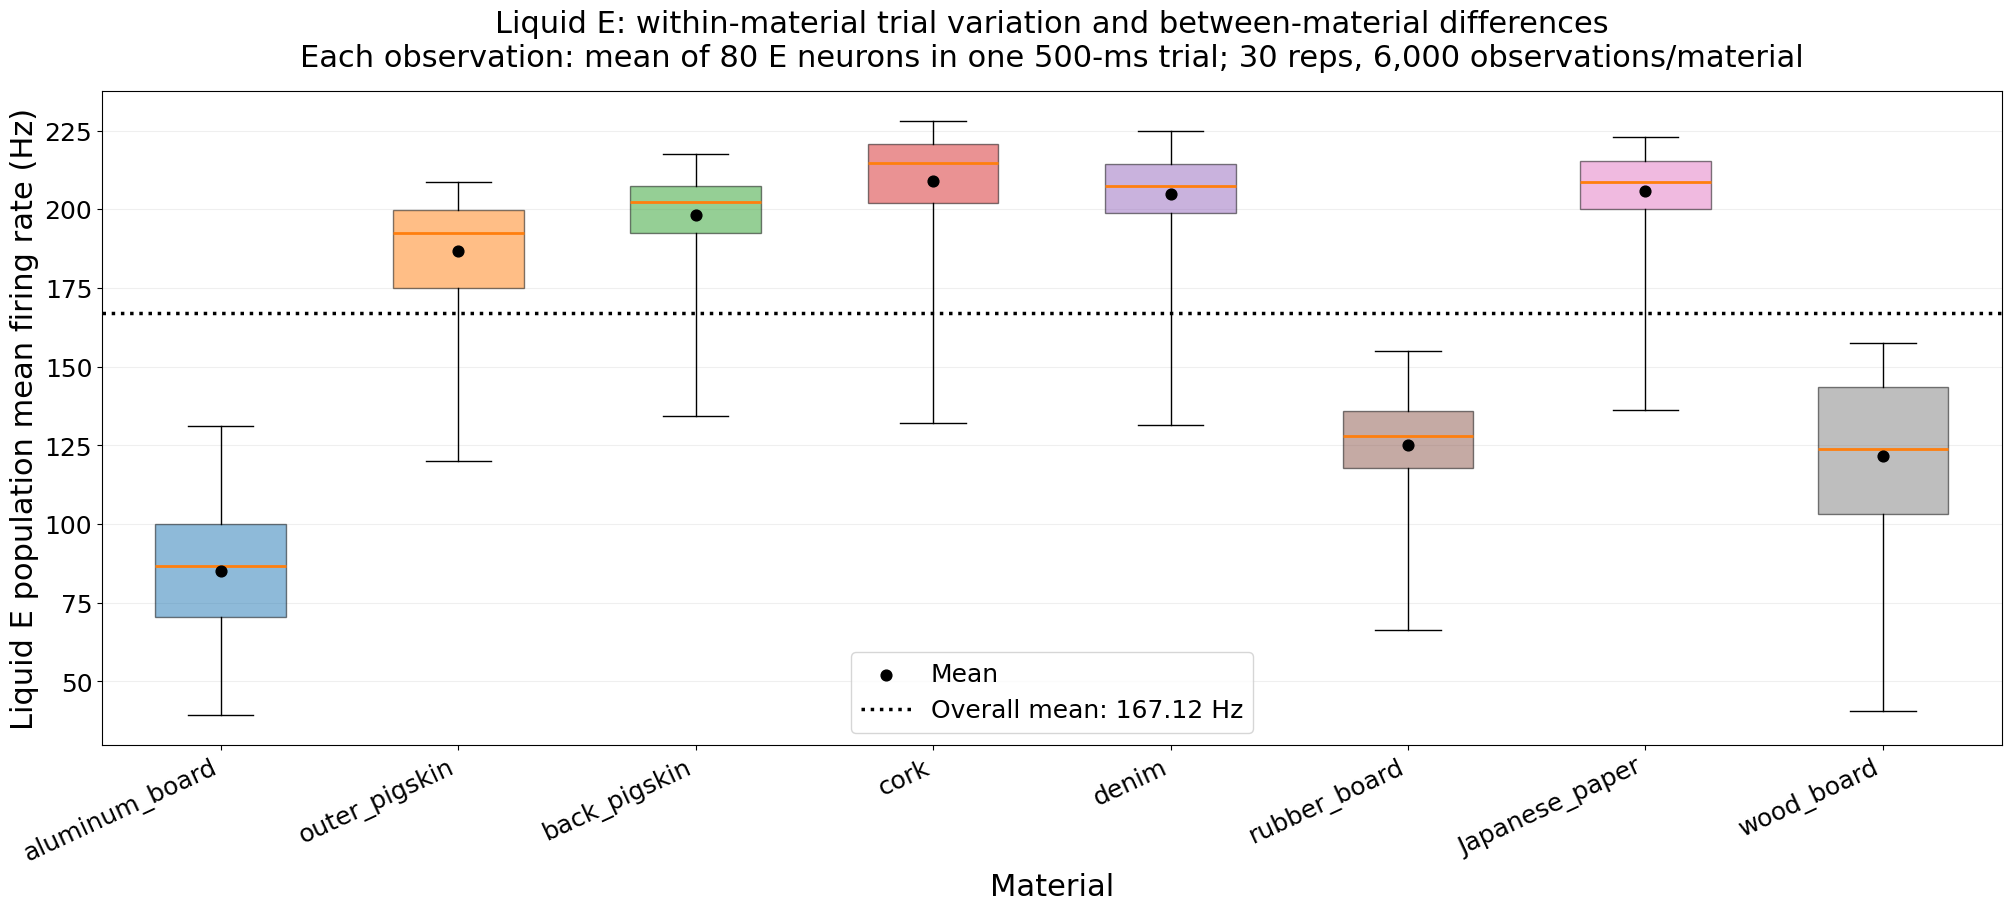

箱：第1～第3四分位、橙線：中央値、ひげ：最小～最大、黒点：平均
各repの試行数/素材：[200]
aluminum_board: 平均 85.210 Hz、SD 21.097 Hz、最小 39.200 Hz、最大 131.275 Hz
outer_pigskin: 平均 186.804 Hz、SD 16.363 Hz、最小 119.975 Hz、最大 208.800 Hz
back_pigskin: 平均 198.265 Hz、SD 13.229 Hz、最小 134.450 Hz、最大 217.600 Hz
cork: 平均 209.090 Hz、SD 15.411 Hz、最小 132.075 Hz、最大 228.150 Hz
denim: 平均 204.941 Hz、SD 14.264 Hz、最小 131.400 Hz、最大 224.725 Hz
rubber_board: 平均 125.121 Hz、SD 15.043 Hz、最小 66.225 Hz、最大 155.050 Hz
Japanese_paper: 平均 205.865 Hz、SD 13.458 Hz、最小 136.225 Hz、最大 222.875 Hz
wood_board: 平均 121.694 Hz、SD 24.927 Hz、最小 40.600 Hz、最大 157.475 Hz


In [3]:
# 各試行のLiquid興奮性ニューロンの平均発火率を、素材別に表示する。
# 先頭セルと同じrepを使用。1観測は「1 repの1試行のEニューロン平均」。
from d_tools.recording_io import read_record

if "used_reps" not in globals():
    raise RuntimeError("先に一番上の混同行列のセルを実行してください。")

material_trial_rates = [[] for _ in materials]
trial_counts_by_rep = []
reference_layers = None
reference_duration_ms = None
for rep in used_reps:
    test_dir = results_root / f"rep{rep}" / "test"
    record_info = read_record(test_dir / "rec" / "recording.npz")
    if record_info["materials"] != materials:
        raise ValueError(f"素材の順序が異なります：rep{rep}")
    if record_info["axis_order"] != ["material", "trial", "neuron", "time_bin"]:
        raise ValueError(f"記録配列の軸の順序が異なります：rep{rep}")
    if record_info["value"] != "spike count per bin":
        raise ValueError(f"発火数の記録ではありません：rep{rep}")
    layers = record_info["liquid_layers"]
    # 各層の「Eの後にI」という保存順から、興奮性ニューロンだけを抽出する。
    excitatory_ids = []
    offset = 0
    for layer in layers:
        excitatory_ids.extend(range(offset, offset + int(layer["n_excitatory"])))
        offset += int(layer["n_excitatory"]) + int(layer["n_inhibitory"])
    if not excitatory_ids:
        raise ValueError(f"興奮性ニューロンがありません：rep{rep}")
    spike_counts = np.load(test_dir / "rec" / "Liquid" / f"sliq_rec_rep{rep}.npy",
                           mmap_mode="r", allow_pickle=False)
    try:
        if spike_counts.ndim != 4 or spike_counts.shape[0] != len(materials) or spike_counts.shape[2] != offset:
            raise ValueError(f"記録配列の形が不正です：rep{rep}")
        duration_ms = spike_counts.shape[-1] * float(record_info["bin_width_ms"])
        if reference_layers is None:
            reference_layers = layers
            reference_duration_ms = duration_ms
        if layers != reference_layers or not np.isclose(duration_ms, reference_duration_ms):
            raise ValueError(f"ニューロン数または試行時間が異なります：rep{rep}")
        trial_counts_by_rep.append(spike_counts.shape[1])
        for material_index in range(len(materials)):
            # 時間方向の発火数合計 / 試行秒数を、全Eニューロンで平均してHzにする。
            trial_rates_hz = (spike_counts[material_index][:, excitatory_ids, :]
                              .sum(axis=(1, 2), dtype=np.float64)
                              / len(excitatory_ids) / (duration_ms / 1000.0))
            material_trial_rates[material_index].append(trial_rates_hz)
    finally:
        spike_counts._mmap.close()

# repごとの試行をまとめる。同じ元試行でもrepが異なれば別の観測として扱う。
material_trial_rates = [np.concatenate(values) for values in material_trial_rates]
mean_rates_hz = np.array([values.mean() for values in material_trial_rates])
# 素材ごとの観測数も反映し、全素材・全rep・全試行の平均を求める。
overall_rate_hz = float(np.concatenate(material_trial_rates).mean())
fig, ax = plt.subplots(figsize=(20, 9), layout="constrained")
boxes = ax.boxplot(material_trial_rates, tick_labels=materials, patch_artist=True,
                   showfliers=False, whis=(0, 100), widths=0.55,
                   medianprops={"color": "tab:orange", "linewidth": 2})
for box, color in zip(boxes["boxes"], plt.get_cmap("tab10").colors):
    box.set_facecolor(color)
    box.set_alpha(0.5)
ax.scatter(np.arange(1, len(materials) + 1), mean_rates_hz,
           color="black", s=60, label="Mean", zorder=3)
ax.axhline(overall_rate_hz, color="black", linestyle=":", linewidth=2.5,
           label=f"Overall mean: {overall_rate_hz:.2f} Hz", zorder=2)
ax.set_ylabel("Liquid E population mean firing rate (Hz)", fontsize=22)
ax.set_xlabel("Material", fontsize=22)
ax.set_title("Liquid E: within-material trial variation and between-material differences\n"
             f"Each observation: mean of {len(excitatory_ids)} E neurons in one {reference_duration_ms:g}-ms trial; "
             f"{len(used_reps)} reps, {len(material_trial_rates[0]):,} observations/material",
             fontsize=22, pad=18)
ax.tick_params(axis="both", labelsize=18)
plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
ax.grid(axis="y", alpha=0.2)
ax.legend(fontsize=18)
plt.show()
print("箱：第1～第3四分位、橙線：中央値、ひげ：最小～最大、黒点：平均")
print(f"各repの試行数/素材：{sorted(set(trial_counts_by_rep))}")
for material, values in zip(materials, material_trial_rates):
    print(f"{material}: 平均 {values.mean():.3f} Hz、SD {values.std(ddof=1):.3f} Hz、"
          f"最小 {values.min():.3f} Hz、最大 {values.max():.3f} Hz")


In [ ]:
# 25 msごとの発火率を使い、開始時刻を25 msずつずらして区間別に評価する。
# 窓幅を25～500 msまで25 msずつ広げ、窓内の25 msビンを特徴量にする。
from concurrent.futures import ThreadPoolExecutor, as_completed
from sklearn.model_selection import StratifiedKFold
from threadpoolctl import threadpool_limits
from tqdm.auto import tqdm
from d_tools.evaluation import extract_features
from d_tools.classification import classify
from d_tools.recording_io import read_record

if "used_reps" not in globals():
    raise RuntimeError("先に混同行列のセルを実行してください。")

WINDOW_STEP_MS = 25
WINDOW_BASE_BIN_MS = 25
WINDOW_DURATION_MS = 500
WINDOW_WIDTHS_MS = list(range(25, 501, 25))
WINDOW_REPS = list(used_reps)
WINDOW_WORKERS = 4
# 25 ms幅なら20区間、50 ms幅なら19区間、500 ms幅なら1区間となる。
# 窓幅と開始位置が、発火率を集約するビン境界に一致することを確認する。
if WINDOW_DURATION_MS % WINDOW_BASE_BIN_MS or WINDOW_STEP_MS % WINDOW_BASE_BIN_MS:
    raise ValueError("試行時間と移動幅は、ビン幅の整数倍にしてください。")
if any(width <= 0 or width > WINDOW_DURATION_MS or width % WINDOW_BASE_BIN_MS for width in WINDOW_WIDTHS_MS):
    raise ValueError("窓幅はビン幅の整数倍で、試行時間以内にしてください。")
window_intervals = [(width, start, start + width)
                    for width in WINDOW_WIDTHS_MS
                    for start in range(0, WINDOW_DURATION_MS - width + 1, WINDOW_STEP_MS)]


def evaluate_liquid_sliding_windows(rep):
    """1 repの全区間を、共通の試行分割でそれぞれ独立に学習・評価する。"""
    test_dir = results_root / f"rep{rep}" / "test"
    info = read_record(test_dir / "test_config_snapshot.json")
    if info["materials"] != materials or info.get("evaluation_population") != "E":
        raise ValueError(f"素材順または評価集団が異なります：rep{rep}")
    ids = np.asarray(info["evaluation_neuron_ids"], dtype=int)
    counts = np.load(test_dir / "rec" / "Liquid" / f"sliq_rec_rep{rep}.npy",
                     mmap_mode="r", allow_pickle=False)
    try:
        bin_ms = float(info["recording_bin_width_ms"])
        if counts.ndim != 4 or not np.isclose(counts.shape[-1] * bin_ms, WINDOW_DURATION_MS):
            raise ValueError(f"500 msの記録が必要です：rep{rep}")
        rates = extract_features(counts[:, :, ids, :], WINDOW_BASE_BIN_MS, bin_width_ms=bin_ms)
        # 試行×ニューロン×時間ビンに戻して、指定された区間だけを切り出す。
        rates = rates.reshape(-1, len(ids), WINDOW_DURATION_MS // WINDOW_BASE_BIN_MS)
        trials_per_material = counts.shape[1]
    finally:
        counts._mmap.close()
    labels = np.repeat(np.arange(len(materials)), trials_per_material)
    cv_seed = int(info["eval"]["EVAL_BASE_SEED"]) + rep - 1
    splits = list(StratifiedKFold(n_splits=folds, shuffle=True, random_state=cv_seed)
                  .split(np.zeros((len(labels), 1)), labels))
    accuracies = []
    for width, start, end in window_intervals:
        features = rates[:, :, start // WINDOW_BASE_BIN_MS:end // WINDOW_BASE_BIN_MS].reshape(len(labels), -1)
        predicted = np.empty_like(labels)
        # 先頭セルの高速な同一距離式があれば使用し、なければ通常の分類器を使う。
        use_gram = features.shape[1] > 160 and "predict_large_feature_fold" in globals()
        gram = features @ features.T if use_gram else None
        for fold_index, (train, test) in enumerate(splits):
            active = np.any(features[train] != 0, axis=0)
            if not active.any():
                raise ValueError(f"学習側に発火がありません：rep{rep}, {start}–{end} ms")
            if use_gram:
                predicted[test] = predict_large_feature_fold(features, labels, train, test, gram)
                # 各窓幅の先頭区間を、既存分類器でも計算して予測の一致を確認する。
                if rep == WINDOW_REPS[0] and start == 0 and fold_index == 0:
                    direct = classify(features[train][:, active], labels[train], features[test][:, active])
                    if not np.array_equal(predicted[test], direct):
                        raise AssertionError(f"通常の分類器と予測が異なります：{start}–{end} ms")
            else:
                predicted[test] = classify(features[train][:, active], labels[train], features[test][:, active])
        accuracy = float(np.mean(predicted == labels) * 100)
        accuracies.append(accuracy)
        # 元の評価とビン幅が同じ場合だけ、全500 msの正答率を照合する。
        if start == 0 and end == WINDOW_DURATION_MS and WINDOW_BASE_BIN_MS == BIN_MS:
            reference = per_rep_accuracies[used_reps.index(rep)]
            if not np.isclose(accuracy, reference):
                raise AssertionError(f"全500 msの正答率が既存結果と一致しません：rep{rep}")
    return rep, accuracies


window_accuracy_by_rep = {}
with threadpool_limits(limits=1):
    with ThreadPoolExecutor(max_workers=min(WINDOW_WORKERS, len(WINDOW_REPS))) as executor:
        jobs = {executor.submit(evaluate_liquid_sliding_windows, rep): rep for rep in WINDOW_REPS}
        for future in tqdm(as_completed(jobs), total=len(jobs), desc="Liquid sliding windows", unit="rep"):
            rep, values = future.result()
            window_accuracy_by_rep[rep] = values
window_accuracy_array = np.asarray([window_accuracy_by_rep[rep] for rep in WINDOW_REPS])
window_accuracy_mean = window_accuracy_array.mean(axis=0)
window_accuracy_sd = (window_accuracy_array.std(axis=0, ddof=1) if len(WINDOW_REPS) > 1
                      else np.zeros(len(window_intervals)))

# 全窓幅を1枚に重ね、各区間の中央時刻で平均正答率を比較する。
fig, ax = plt.subplots(figsize=(20, 10), layout="constrained")
window_colors = plt.get_cmap("tab20")
for width_index, width in enumerate(WINDOW_WIDTHS_MS):
    indices = [i for i, interval in enumerate(window_intervals) if interval[0] == width]
    # 例：0–25 msの点は12.5 ms、0–100 msの点は50 msへ配置する。
    centers = np.asarray([(window_intervals[i][1] + window_intervals[i][2]) / 2
                          for i in indices])
    means, deviations = window_accuracy_mean[indices], window_accuracy_sd[indices]
    ax.errorbar(centers, means, yerr=deviations, fmt="o-", linewidth=1.8,
                markersize=5, capsize=2, color=window_colors(width_index % 20),
                label=f"{width} ms")
ax.set_xlabel("Evaluation interval center (ms)", fontsize=22)
ax.set_ylabel("Classification accuracy (%)", fontsize=22)
ax.set_title(f"Liquid E | Window widths: 25–500 ms | Step: {WINDOW_STEP_MS} ms | {len(WINDOW_REPS)} reps\n"
             f"{WINDOW_BASE_BIN_MS}-ms features; {folds}-fold stratified CV; mean ± SD across reps",
             fontsize=22, pad=18)
ax.set_xlim(0, WINDOW_DURATION_MS)
ax.set_xticks(np.arange(0, WINDOW_DURATION_MS + 1, 25))
ax.set_ylim(0, 105)
ax.axhline(100 / len(materials), color="gray", linestyle=":",
           label=f"Chance: {100 / len(materials):g}%")
ax.tick_params(axis="both", labelsize=16)
ax.grid(alpha=0.2)
ax.legend(title="Window width", fontsize=12, title_fontsize=14,
          loc="upper left", bbox_to_anchor=(1.01, 1), ncol=2)
plt.show()
print(f"{len(window_intervals)}区間 × {len(WINDOW_REPS)} repを評価しました。")
print(f"各ニューロンの{WINDOW_BASE_BIN_MS} msごとの発火率を使い、窓内のビンだけを連結しています。")


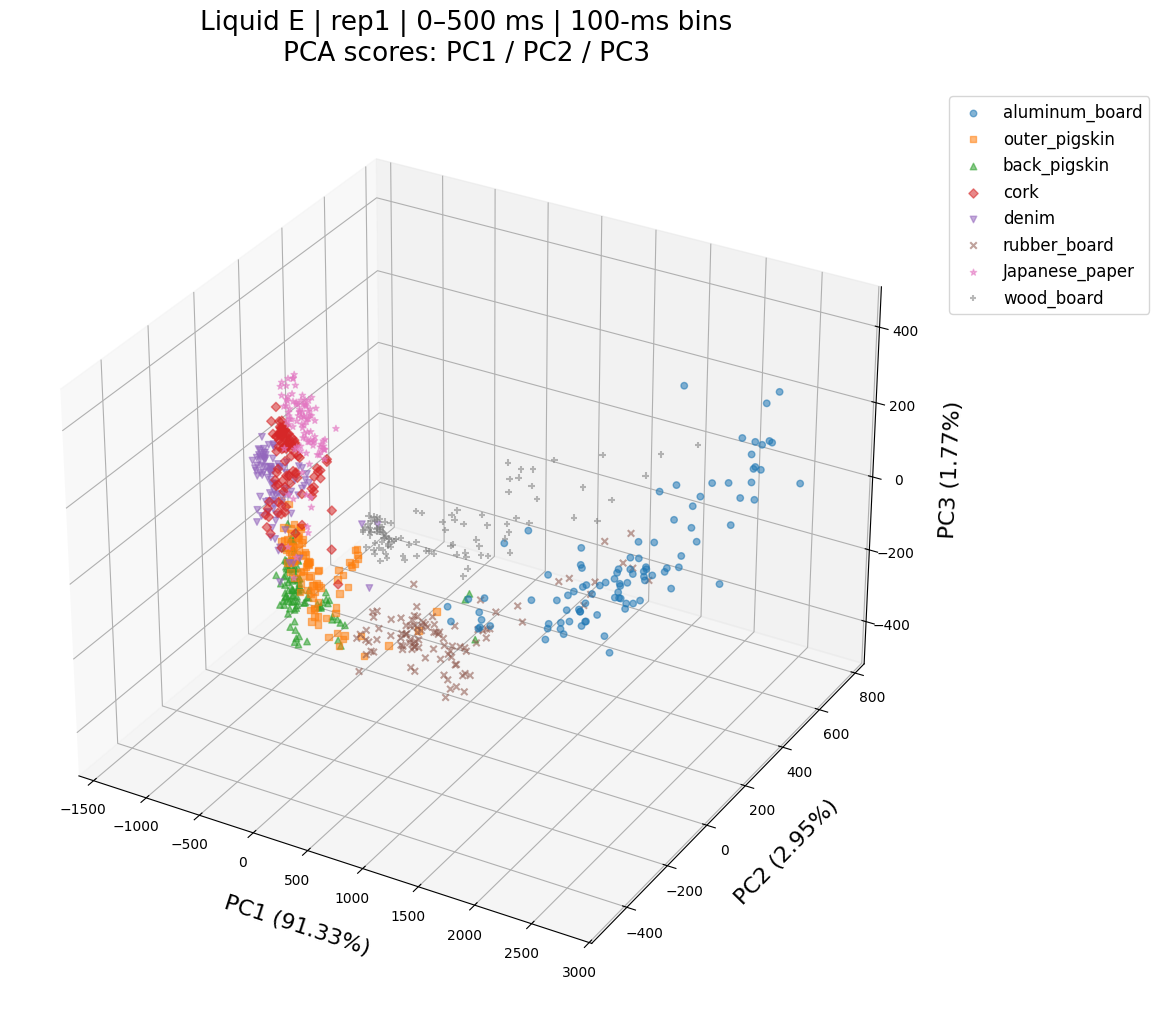

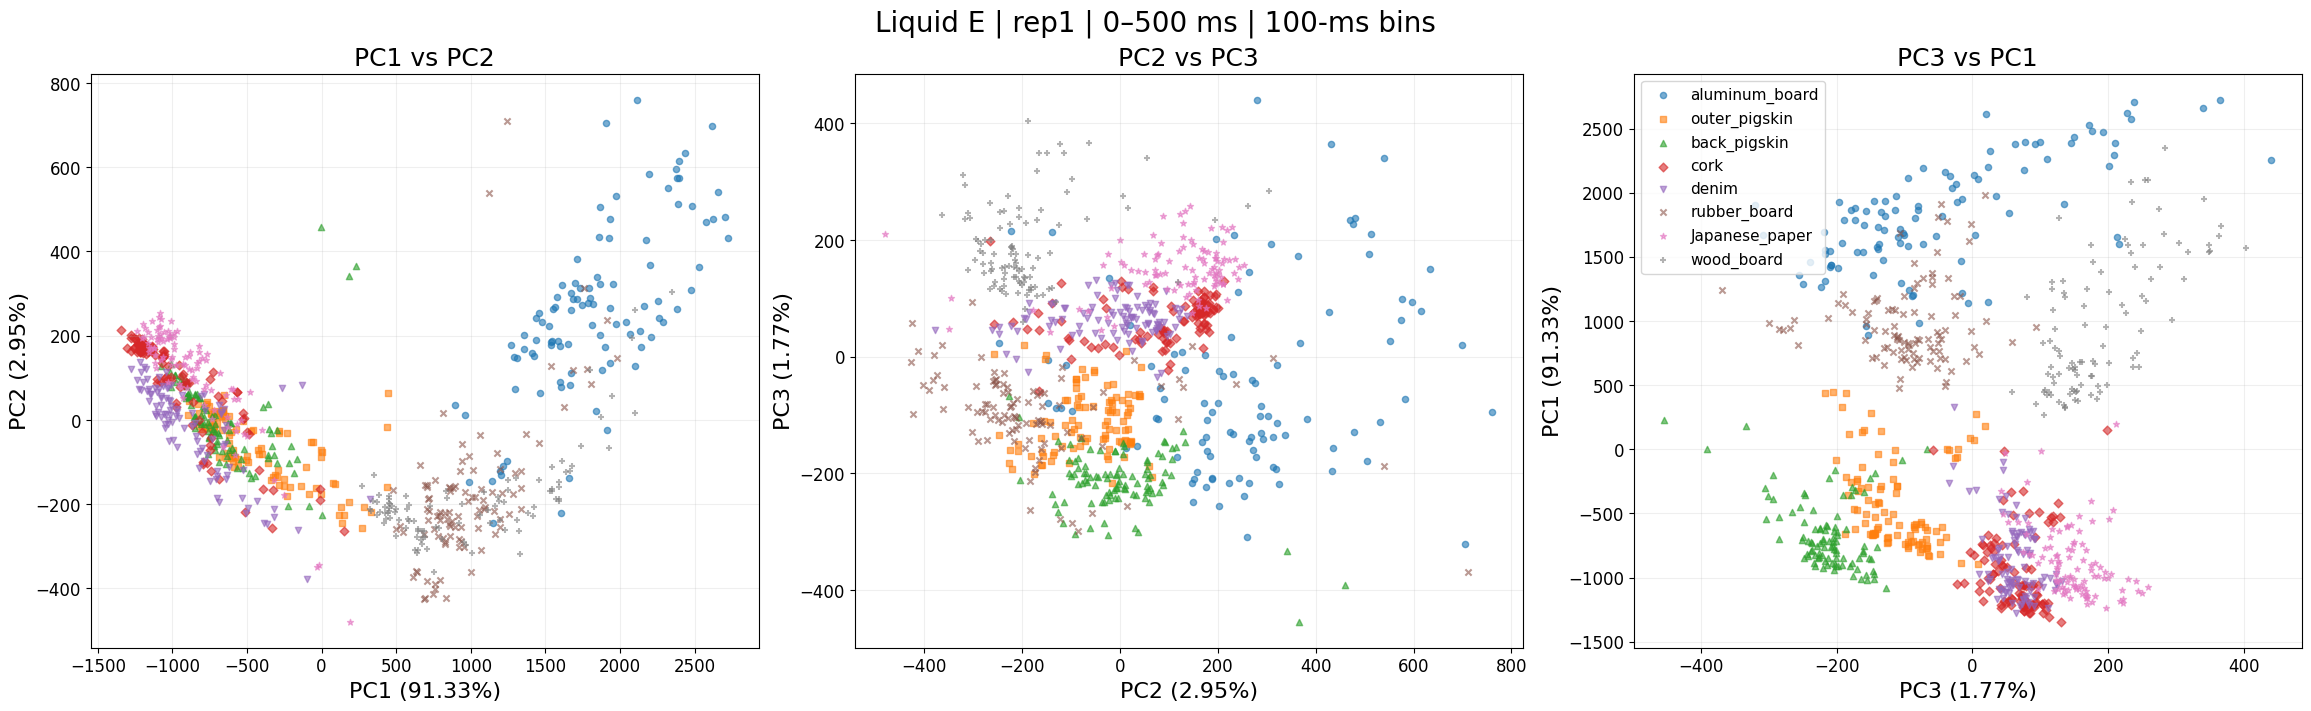

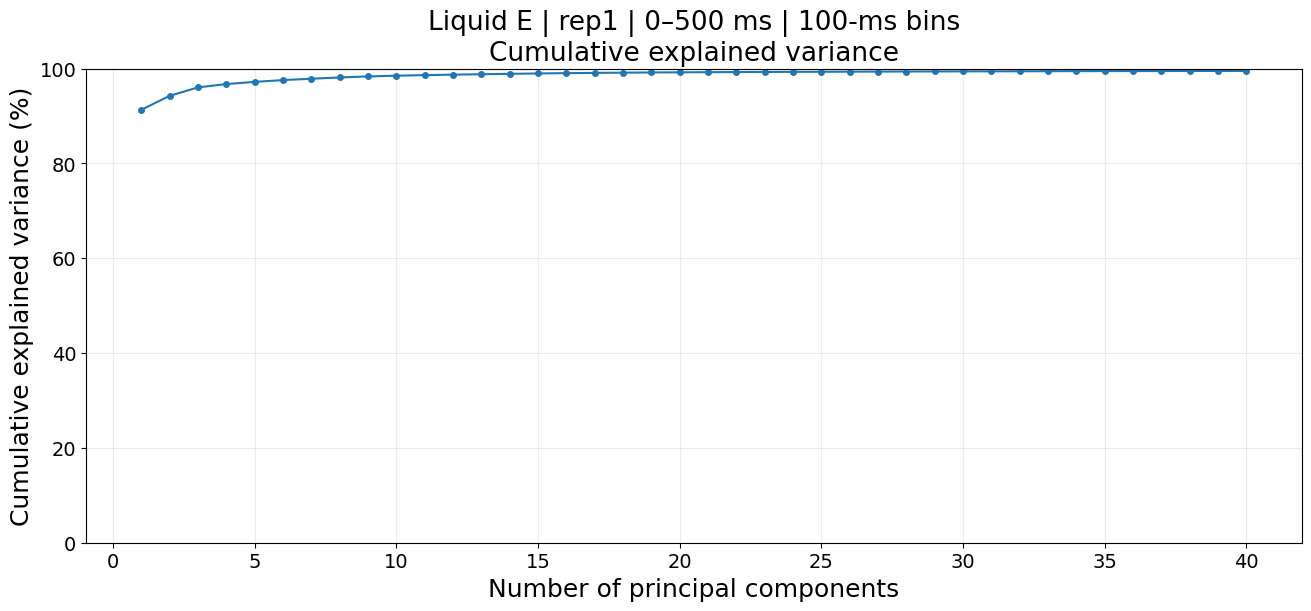

rep1、0–500 ms、100試行/素材
PCA入力：(800, 80, 5)（全試行 × Eニューロン × 時間ビン）
全試行で平均を引いてPCAを計算した可視化です。標準化はせず、分類精度の評価には使用していません。


In [4]:
# 指定したrep・時間窓だけをPCAで可視化する。このセル単独で実行できる。
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits

# ここを変更して表示する試行群と時間窓を選ぶ。
PCA_REP = 1
PCA_START_MS = 0
PCA_WIDTH_MS = 500
PCA_BIN_MS = 100
PCA_COMPONENTS = 40

# 実行場所に依存せずLSMを探し、共通のPCA処理を使う。
pca_root = next((root for parent in (Path.cwd(), *Path.cwd().parents)
                 for root in (parent, parent / "LSM")
                 if (root / "d_tools" / "pca.py").is_file()), None)
if pca_root is None:
    raise FileNotFoundError("LSMフォルダからノートブックを開いてください。")
if str(pca_root) not in sys.path:
    sys.path.insert(0, str(pca_root))
from d_tools.recording_io import read_record
from d_tools.evaluation import extract_features
from d_tools.pca import fit_transform_pca

for name, value in {"PCA_REP": PCA_REP, "PCA_START_MS": PCA_START_MS,
                    "PCA_WIDTH_MS": PCA_WIDTH_MS, "PCA_BIN_MS": PCA_BIN_MS,
                    "PCA_COMPONENTS": PCA_COMPONENTS}.items():
    if isinstance(value, bool) or not isinstance(value, (int, np.integer)):
        raise ValueError(f"{name}には整数を指定してください。")
if PCA_REP < 1 or PCA_START_MS < 0 or PCA_WIDTH_MS <= 0 or PCA_BIN_MS <= 0 or PCA_COMPONENTS < 3:
    raise ValueError("repは1以上、開始は0以上、幅・ビン幅は正、主成分数は3以上にしてください。")
if PCA_START_MS % PCA_BIN_MS or PCA_WIDTH_MS % PCA_BIN_MS:
    raise ValueError("開始時刻と窓幅はPCA_BIN_MSの整数倍にしてください。")
pca_dir = pca_root / "g_tactile_results" / "liquid_run" / f"rep{PCA_REP}" / "test"
pca_info = read_record(pca_dir / "test_config_snapshot.json")
if pca_info.get("evaluation_population") != "E":
    raise ValueError("このセルはLiquid興奮性ニューロンの保存記録を対象にしています。")
pca_materials = list(pca_info["materials"])
pca_neuron_ids = np.asarray(pca_info["evaluation_neuron_ids"], dtype=int)
pca_record_bin_ms = float(pca_info["recording_bin_width_ms"])
pca_end_ms = PCA_START_MS + PCA_WIDTH_MS
pca_counts = np.load(pca_dir / "rec" / "Liquid" / f"sliq_rec_rep{PCA_REP}.npy",
                     mmap_mode="r", allow_pickle=False)
try:
    if pca_counts.ndim != 4 or pca_counts.shape[0] != len(pca_materials):
        raise ValueError("保存記録の配列の形または素材数が不正です。")
    if pca_end_ms > pca_counts.shape[-1] * pca_record_bin_ms:
        raise ValueError("指定した窓が試行の終了時刻を超えています。")
    if not np.isclose(PCA_START_MS / pca_record_bin_ms, round(PCA_START_MS / pca_record_bin_ms)):
        raise ValueError("開始時刻が記録の時間ビンに一致しません。")
    pca_start_bin = round(PCA_START_MS / pca_record_bin_ms)
    pca_end_bin = round(pca_end_ms / pca_record_bin_ms)
    pca_n_trials = pca_counts.shape[1]
    # 窓外を除き、窓内の25 msビン×Eニューロンを特徴量にする。
    pca_features = extract_features(pca_counts[:, :, pca_neuron_ids, pca_start_bin:pca_end_bin],
                                    PCA_BIN_MS, bin_width_ms=pca_record_bin_ms)
    pca_states = pca_features.reshape(len(pca_materials) * pca_n_trials,
                                     len(pca_neuron_ids), PCA_WIDTH_MS // PCA_BIN_MS)
finally:
    pca_counts._mmap.close()
if not np.any(np.var(pca_states, axis=0) > 0):
    raise ValueError("指定した区間の試行間変動がないため、PCAを表示できません。")
pca_n_components = min(PCA_COMPONENTS, pca_states.shape[0] - 1,
                        pca_states.shape[1] * pca_states.shape[2])
with threadpool_limits(limits=1):
    pca_scores, pca_model = fit_transform_pca(pca_states, n_components=pca_n_components)
pca_percent = np.maximum(pca_model.explained_variance, 0) / pca_model.total_variance * 100
pca_labels = np.repeat(np.arange(len(pca_materials)), pca_n_trials)
pca_note = f"Liquid E | rep{PCA_REP} | {PCA_START_MS}–{pca_end_ms} ms | {PCA_BIN_MS}-ms bins"
pca_colors = plt.get_cmap("tab10").colors
pca_markers = ["o", "s", "^", "D", "v", "x", "*", "+"]

# 各点は1試行。色は素材を表し、全素材を共通のPCA軸に投影する。
fig = plt.figure(figsize=(13, 10), layout="constrained")
ax = fig.add_subplot(111, projection="3d")
for index, material in enumerate(pca_materials):
    points = pca_scores[pca_labels == index]
    ax.scatter(points[:, 0], points[:, 1], points[:, 2], color=pca_colors[index],
               marker=pca_markers[index], s=22, alpha=0.55, label=material)
ax.set_xlabel(f"PC1 ({pca_percent[0]:.2f}%)", fontsize=16, labelpad=14)
ax.set_ylabel(f"PC2 ({pca_percent[1]:.2f}%)", fontsize=16, labelpad=14)
ax.set_zlabel(f"PC3 ({pca_percent[2]:.2f}%)", fontsize=16, labelpad=14)
ax.set_title(pca_note + "\nPCA scores: PC1 / PC2 / PC3", fontsize=19, pad=20)
ax.legend(fontsize=12, loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

# 同じスコアを3組の2次元平面で表示する。
fig, axes = plt.subplots(1, 3, figsize=(23, 7), layout="constrained")
for ax, (horizontal, vertical) in zip(axes, [(0, 1), (1, 2), (2, 0)]):
    for index, material in enumerate(pca_materials):
        points = pca_scores[pca_labels == index]
        ax.scatter(points[:, horizontal], points[:, vertical], color=pca_colors[index],
                   marker=pca_markers[index], s=20, alpha=0.6, label=material)
    ax.set_xlabel(f"PC{horizontal + 1} ({pca_percent[horizontal]:.2f}%)", fontsize=16)
    ax.set_ylabel(f"PC{vertical + 1} ({pca_percent[vertical]:.2f}%)", fontsize=16)
    ax.set_title(f"PC{horizontal + 1} vs PC{vertical + 1}", fontsize=18)
    ax.tick_params(labelsize=12)
    ax.grid(alpha=0.2)
axes[-1].legend(fontsize=11, loc="best")
fig.suptitle(pca_note, fontsize=20)
plt.show()

fig, ax = plt.subplots(figsize=(13, 6), layout="constrained")
ax.plot(np.arange(1, pca_n_components + 1), np.cumsum(pca_percent), "o-", markersize=4)
ax.set_xlabel("Number of principal components", fontsize=18)
ax.set_ylabel("Cumulative explained variance (%)", fontsize=18)
ax.set_title(pca_note + "\nCumulative explained variance", fontsize=19)
ax.set_ylim(0, 100)
ax.tick_params(labelsize=14)
ax.grid(alpha=0.25)
plt.show()
print(f"rep{PCA_REP}、{PCA_START_MS}–{pca_end_ms} ms、{pca_n_trials}試行/素材")
print(f"PCA入力：{pca_states.shape}（全試行 × Eニューロン × 時間ビン）")
print("全試行で平均を引いてPCAを計算した可視化です。標準化はせず、分類精度の評価には使用していません。")


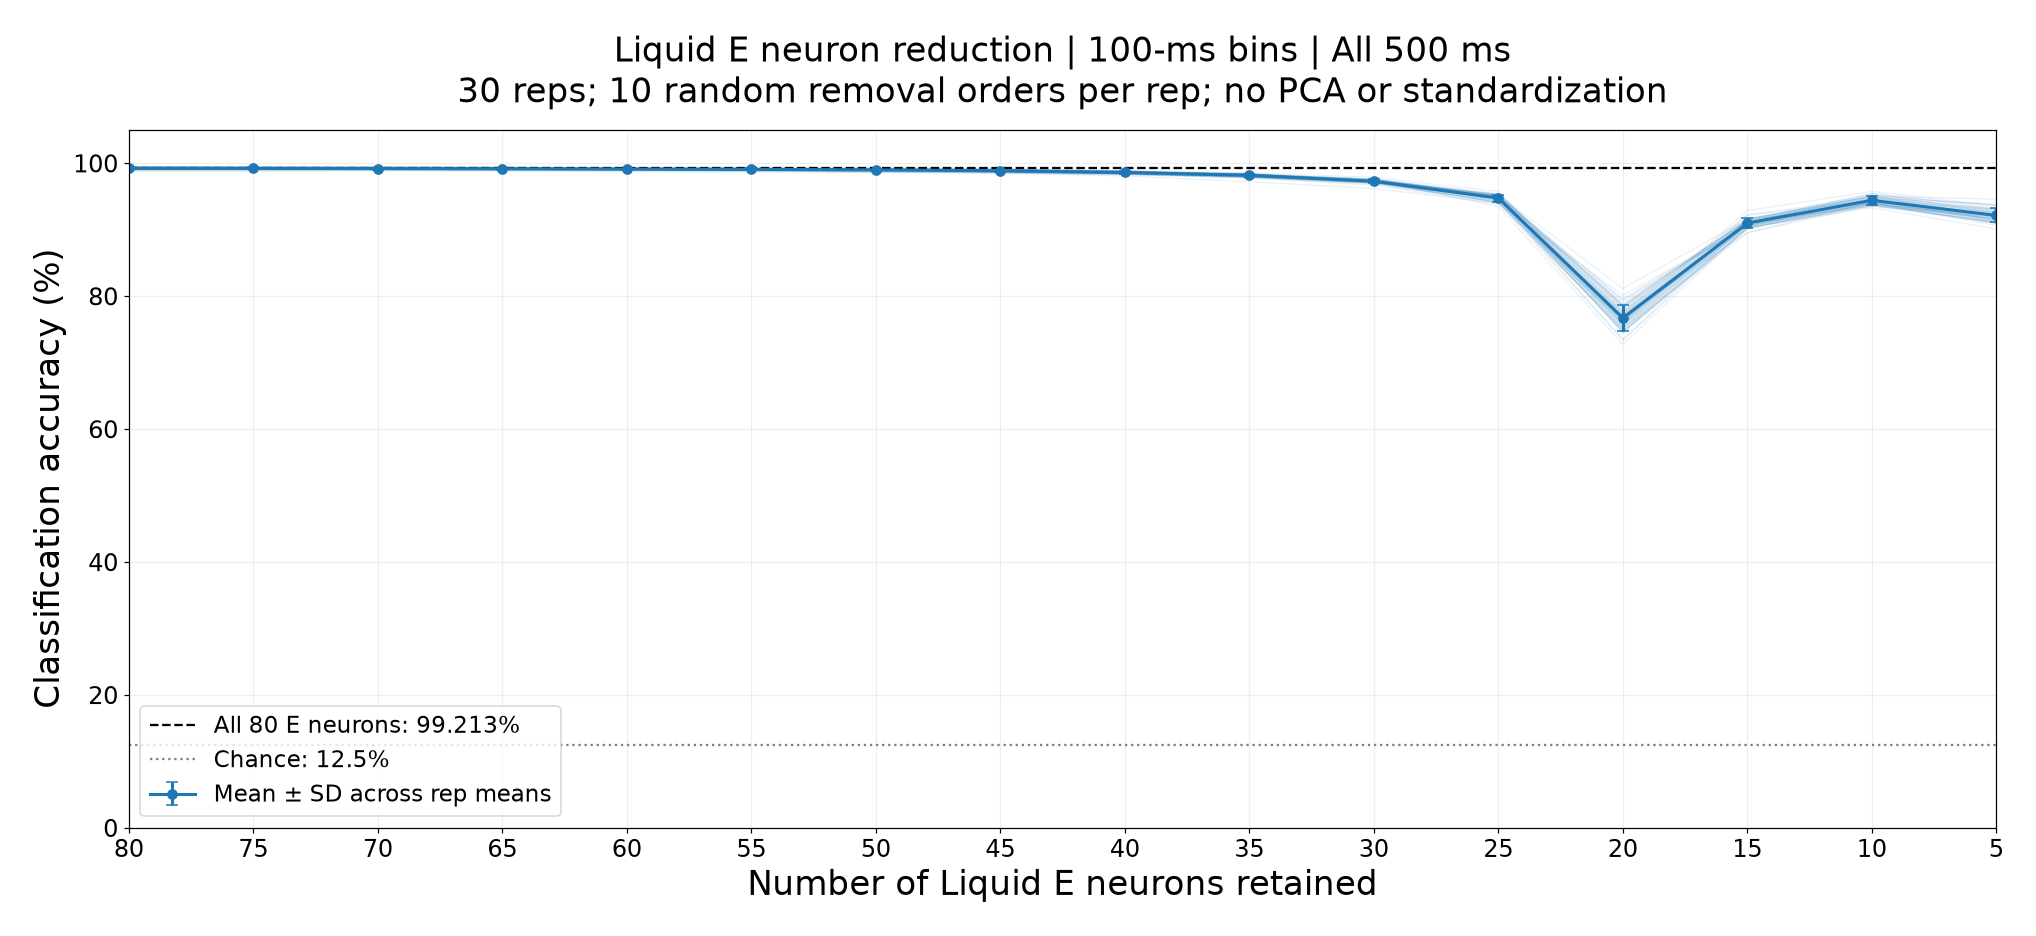

対象rep：[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
ニューロン数   平均正答率(%)   rep間SD(ポイント)
      80         99.213          0.165
      75         99.196          0.163
      70         99.179          0.150
      65         99.142          0.141
      60         99.094          0.129
      55         99.055          0.152
      50         98.975          0.173
      45         98.843          0.180
      40         98.583          0.196
      35         98.144          0.261
      30         97.261          0.310
      25         94.737          0.523
      20         76.681          2.010
      15         90.964          0.725
      10         94.392          0.644
       5         92.125          1.065
選択したニューロンの全時間ビンを使用し、各repの試行分割はすべての条件で共通です。


In [6]:
# Liquid Eの評価に使うニューロンだけを減らす。記録済みの発火や結合は変更しない。
from pathlib import Path
import sys
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from threadpoolctl import threadpool_limits
from tqdm.auto import tqdm

# 評価条件。各ランダム順序の先頭から選び、ニューロン集合を入れ子にして減らす。
NEURON_BIN_MS = 100
NEURON_COUNTS = list(range(80, 0, -5))
NEURON_RANDOM_SELECTIONS = 10
NEURON_REPS = None  # Noneなら保存済みの全rep。例：[1, 2, 3, 4, 5]
NEURON_SELECTION_SEED = 20261031
NEURON_WORKERS = 4

reduction_project_root = next((root for parent in (Path.cwd(), *Path.cwd().parents)
                               for root in (parent, parent / "LSM")
                               if (root / "d_tools" / "classification.py").is_file()), None)
if reduction_project_root is None:
    raise FileNotFoundError("LSMフォルダからノートブックを開いてください。")
if str(reduction_project_root) not in sys.path:
    sys.path.insert(0, str(reduction_project_root))
from d_tools.recording_io import read_record
from d_tools.evaluation import extract_features
from d_tools.classification import classify

reduction_root = reduction_project_root / "g_tactile_results" / "liquid_run"
reduction_available_reps = sorted(int(folder.name[3:]) for folder in reduction_root.glob("rep*")
                                  if folder.is_dir() and folder.name[3:].isdigit()
                                  and (folder / "test" / "test_config_snapshot.json").is_file()
                                  and (folder / "test" / "rec" / "Liquid" / f"sliq_rec_{folder.name}.npy").is_file())
reduction_reps = reduction_available_reps if NEURON_REPS is None else list(NEURON_REPS)
if not reduction_reps or len(set(reduction_reps)) != len(reduction_reps) or not set(reduction_reps).issubset(reduction_available_reps):
    raise ValueError("保存済みのrepを重複なく指定してください。")
if NEURON_RANDOM_SELECTIONS < 1 or NEURON_WORKERS < 1:
    raise ValueError("選択回数と並列数は1以上にしてください。")
if not NEURON_COUNTS or len(set(NEURON_COUNTS)) != len(NEURON_COUNTS) or any(
        isinstance(count, bool) or not isinstance(count, (int, np.integer)) or count < 1 for count in NEURON_COUNTS):
    raise ValueError("ニューロン数には重複しない正の整数を指定してください。")
reduction_reference_info = read_record(reduction_root / f"rep{reduction_reps[0]}" / "test" / "test_config_snapshot.json")
reduction_materials = list(reduction_reference_info["materials"])
reduction_population_size = len(reduction_reference_info["evaluation_neuron_ids"])
if max(NEURON_COUNTS) > reduction_population_size:
    raise ValueError("保存記録のEニューロン数を超えています。")


def evaluate_liquid_neuron_reduction(rep):
    """同一rep内でCV分割を固定し、各ニューロン集合について分類器を再学習する。"""
    test_dir = reduction_root / f"rep{rep}" / "test"
    info = read_record(test_dir / "test_config_snapshot.json")
    if info.get("evaluation_population") != "E" or info["materials"] != reduction_materials:
        raise ValueError(f"評価集団または素材順が異なります：rep{rep}")
    ids = np.asarray(info["evaluation_neuron_ids"], dtype=int)
    if len(ids) != reduction_population_size:
        raise ValueError(f"Eニューロン数が異なります：rep{rep}")
    recorded = np.load(test_dir / "rec" / "Liquid" / f"sliq_rec_rep{rep}.npy",
                       mmap_mode="r", allow_pickle=False)
    try:
        record_bin_ms = float(info["recording_bin_width_ms"])
        if recorded.ndim != 4 or not np.isclose(recorded.shape[-1] * record_bin_ms, 500):
            raise ValueError(f"500 msの発火記録が必要です：rep{rep}")
        rates = extract_features(recorded[:, :, ids, :], NEURON_BIN_MS, bin_width_ms=record_bin_ms)
        rates = rates.reshape(-1, len(ids), round(500 / NEURON_BIN_MS))
        trials_per_material = recorded.shape[1]
    finally:
        recorded._mmap.close()
    labels = np.repeat(np.arange(len(reduction_materials)), trials_per_material)
    cv = StratifiedKFold(n_splits=int(info["eval"]["EVAL_N_FOLDS"]), shuffle=True,
                         random_state=int(info["eval"]["EVAL_BASE_SEED"]) + rep - 1)
    splits = list(cv.split(np.zeros((len(labels), 1)), labels))

    def score(selected):
        """選択した全ニューロンの500 ms分を連結し、out-of-fold正答率を返す。"""
        features = rates[:, selected, :].reshape(len(labels), -1)
        predicted = np.empty_like(labels)
        for train, test in splits:
            active = np.any(features[train] != 0, axis=0)
            if active.any():
                predicted[test] = classify(features[train][:, active], labels[train], features[test][:, active])
            else:
                # 選んだ全ニューロンが無活動なら、学習側の最多クラスで予測する。
                predicted[test] = np.argmax(np.bincount(labels[train], minlength=len(reduction_materials)))
        return float(np.mean(predicted == labels) * 100)

    # 全80個ではどの選択順も同じなので、重複した10回の計算を避ける。
    full_accuracy = score(np.arange(len(ids)))
    values = np.empty((NEURON_RANDOM_SELECTIONS, len(NEURON_COUNTS)))
    for order in range(NEURON_RANDOM_SELECTIONS):
        rng = np.random.default_rng(np.random.SeedSequence([NEURON_SELECTION_SEED, rep, order]))
        permutation = rng.permutation(len(ids))
        for index, count in enumerate(NEURON_COUNTS):
            values[order, index] = (full_accuracy if count == len(ids)
                                    else score(np.sort(permutation[:count])))
    return rep, values, full_accuracy


reduction_results = {}
reduction_full_accuracy_by_rep = {}
with threadpool_limits(limits=1):
    with ThreadPoolExecutor(max_workers=min(NEURON_WORKERS, len(reduction_reps))) as executor:
        jobs = {executor.submit(evaluate_liquid_neuron_reduction, rep): rep for rep in reduction_reps}
        for future in tqdm(as_completed(jobs), total=len(jobs), desc="Liquid E neuron reduction", unit="rep"):
            rep, values, full_accuracy = future.result()
            reduction_results[rep] = values
            reduction_full_accuracy_by_rep[rep] = full_accuracy
reduction_accuracy_array = np.asarray([reduction_results[rep] for rep in reduction_reps])
# 先に各rep内のランダム選択を平均し、そのrep平均の平均・標本標準偏差を表示する。
reduction_rep_means = reduction_accuracy_array.mean(axis=1)
reduction_accuracy_mean = reduction_rep_means.mean(axis=0)
reduction_accuracy_sd = (reduction_rep_means.std(axis=0, ddof=1) if len(reduction_reps) > 1
                          else np.zeros(len(NEURON_COUNTS)))
reduction_full_mean = float(np.mean(list(reduction_full_accuracy_by_rep.values())))
fig, ax = plt.subplots(figsize=(18, 8), layout="constrained")
for rep_means in reduction_rep_means:
    ax.plot(NEURON_COUNTS, rep_means, color="tab:blue", alpha=0.10, linewidth=0.8)
ax.errorbar(NEURON_COUNTS, reduction_accuracy_mean, yerr=reduction_accuracy_sd,
            fmt="o-", capsize=4, linewidth=2, label="Mean ± SD across rep means")
ax.fill_between(NEURON_COUNTS, reduction_accuracy_mean - reduction_accuracy_sd,
                reduction_accuracy_mean + reduction_accuracy_sd, color="tab:blue", alpha=0.15)
ax.axhline(reduction_full_mean, color="black", linestyle="--",
           label=f"All {reduction_population_size} E neurons: {reduction_full_mean:.3f}%")
ax.axhline(100 / len(reduction_materials), color="gray", linestyle=":",
           label=f"Chance: {100 / len(reduction_materials):g}%")
ax.set_xticks(NEURON_COUNTS)
ax.set_xlim(max(NEURON_COUNTS), min(NEURON_COUNTS))
ax.set_ylim(0, 105)
ax.set_xlabel("Number of Liquid E neurons retained", fontsize=22)
ax.set_ylabel("Classification accuracy (%)", fontsize=22)
ax.set_title(f"Liquid E neuron reduction | {NEURON_BIN_MS}-ms bins | All 500 ms\n"
             f"{len(reduction_reps)} reps; {NEURON_RANDOM_SELECTIONS} random removal orders per rep; no PCA or standardization",
             fontsize=22, pad=18)
ax.tick_params(labelsize=16)
ax.grid(alpha=0.2)
ax.legend(fontsize=15, loc="lower left")
plt.show()
print(f"対象rep：{reduction_reps}")
print("ニューロン数   平均正答率(%)   rep間SD(ポイント)")
for count, mean, sd in zip(NEURON_COUNTS, reduction_accuracy_mean, reduction_accuracy_sd):
    print(f"{count:8d}     {mean:10.3f}     {sd:10.3f}")
print("選択したニューロンの全時間ビンを使用し、各repの試行分割はすべての条件で共通です。")
